## Análisis Exploratorio y Formateo de datos

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, coint
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('../data/raw/historico_equipos.csv')
df

,Date,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
0,2010-01-04,80.12,527.50,2225.25,434.73,931.73
1,2010-01-05,80.59,527.50,2246.50,449.97,968.56
2,2010-01-06,81.89,527.50,2302.50,444.48,960.51
3,2010-01-07,81.51,527.50,2306.50,440.90,960.14
4,2010-01-08,81.37,552.50,2261.25,448.82,949.55
...,...,...,...,...,...,...
3525,2023-08-25,84.48,554.00,2123.50,450.36,899.65
3526,2023-08-28,84.42,549.00,2116.25,469.03,933.20
3527,2023-08-29,85.49,545.33,2116.25,460.42,901.79
3528,2023-08-30,85.86,543.67,2140.25,464.80,945.40


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3530 entries, 0 to 3529
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           3530 non-null   str    
 1   Price_X        3530 non-null   float64
 2   Price_Y        3530 non-null   float64
 3   Price_Z        3530 non-null   float64
 4   Price_Equipo1  3530 non-null   float64
 5   Price_Equipo2  3530 non-null   float64
dtypes: float64(5), str(1)
memory usage: 165.6 KB


In [5]:
df.dtypes

Date                 str
Price_X          float64
Price_Y          float64
Price_Z          float64
Price_Equipo1    float64
Price_Equipo2    float64
dtype: object

Se da el formato correcto a fechas y se establece como índice para poder llevar a cabo el análisis temporal. No es necesario mantener observaciones diarias, eso únicamente agregaría ruido y dado que el requerimiento de negocio es planeación a meses, se transforman los datos temporales a mensuales en lugar de diarios

In [6]:
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df_por_mes = df.resample('ME').mean()

In [7]:
df_por_mes

,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-01-31,77.013000,547.000000,2234.325000,451.818000,945.189500
2010-02-28,74.790000,538.000000,2048.575000,444.143500,886.575000
2010-03-31,79.931304,606.630435,2204.130435,501.005217,965.705652
2010-04-30,85.753810,682.976190,2313.083333,562.120476,1025.756667
2010-05-31,76.997619,679.642857,2048.666667,558.783333,932.173333
...,...,...,...,...,...
2023-04-30,83.368947,603.885789,2336.763158,503.402105,1009.561053
2023-05-31,75.694783,550.593913,2271.586957,457.468696,964.018261
2023-06-30,74.978636,541.775909,2180.738636,449.975909,931.185455


In [8]:
print("Dimensiones diarias:", df.shape)
print("Dimensiones mensuales:", df_por_mes.shape)
display(df_por_mes.head())

Dimensiones diarias: (3530, 5)
Dimensiones mensuales: (164, 5)


,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-01-31,77.013000,547.000000,2234.325000,451.818000,945.189500
2010-02-28,74.790000,538.000000,2048.575000,444.143500,886.575000
2010-03-31,79.931304,606.630435,2204.130435,501.005217,965.705652
2010-04-30,85.753810,682.976190,2313.083333,562.120476,1025.756667
2010-05-31,76.997619,679.642857,2048.666667,558.783333,932.173333


### Prueba de estadística Dickey-Fuller
Se aplicó Dickey-Fuller para saber si los precios de las materias primas se comportan de forma estacionaria o no, considerando como hipótesis nula (H0) que la serie no es estacionaria, en caso de que p-value > 0.05 se confirma que no es estacionaria. En este caso los precios de X y Y son no estacionarias, a diferencia de Z que resultó ser Estacionaria, el p-value de esta última está en el límite por lo que puede considerarse como casi integrada.

In [ ]:
print("Prueba de Estacionariedad Dickey-Fuller")
for col in ['Price_X', 'Price_Y', 'Price_Z']:
    # Aunque no existen nulos se excluyen como buena práctica
    resultado_adf = adfuller(df_por_mes[col].dropna())
    p_value = resultado_adf[1]
    
    if p_value > 0.05:
        print(f"{col}: No es estacionaria (p-value: {p_value:.4f}) I(1)")
    else:
        print(f"{col}: Es estacionaria (p-value: {p_value:.4f}) I(0)")

print("\n")

Prueba de Estacionariedad Dickey-Fuller
Price_X: No es estacionaria (p-value: 0.4036) I(1)
Price_Y: No es estacionaria (p-value: 0.3036) I(1)
Price_Z: Es estacionaria (p-value: 0.0428) I(0)




### Evolución de precios y costos

A pesar de que las variaciones de la materia prima X podrían percibirse como estacionarias dadas sus "pocas variacioes", con la prueba de Dickey-Fuller se comprobó que no es estacionaria y Z a diferencia de lo que se puede observar sí lo es. La estacionariedad de una serie temporal no puede basarse únicamente en visualizaciones.


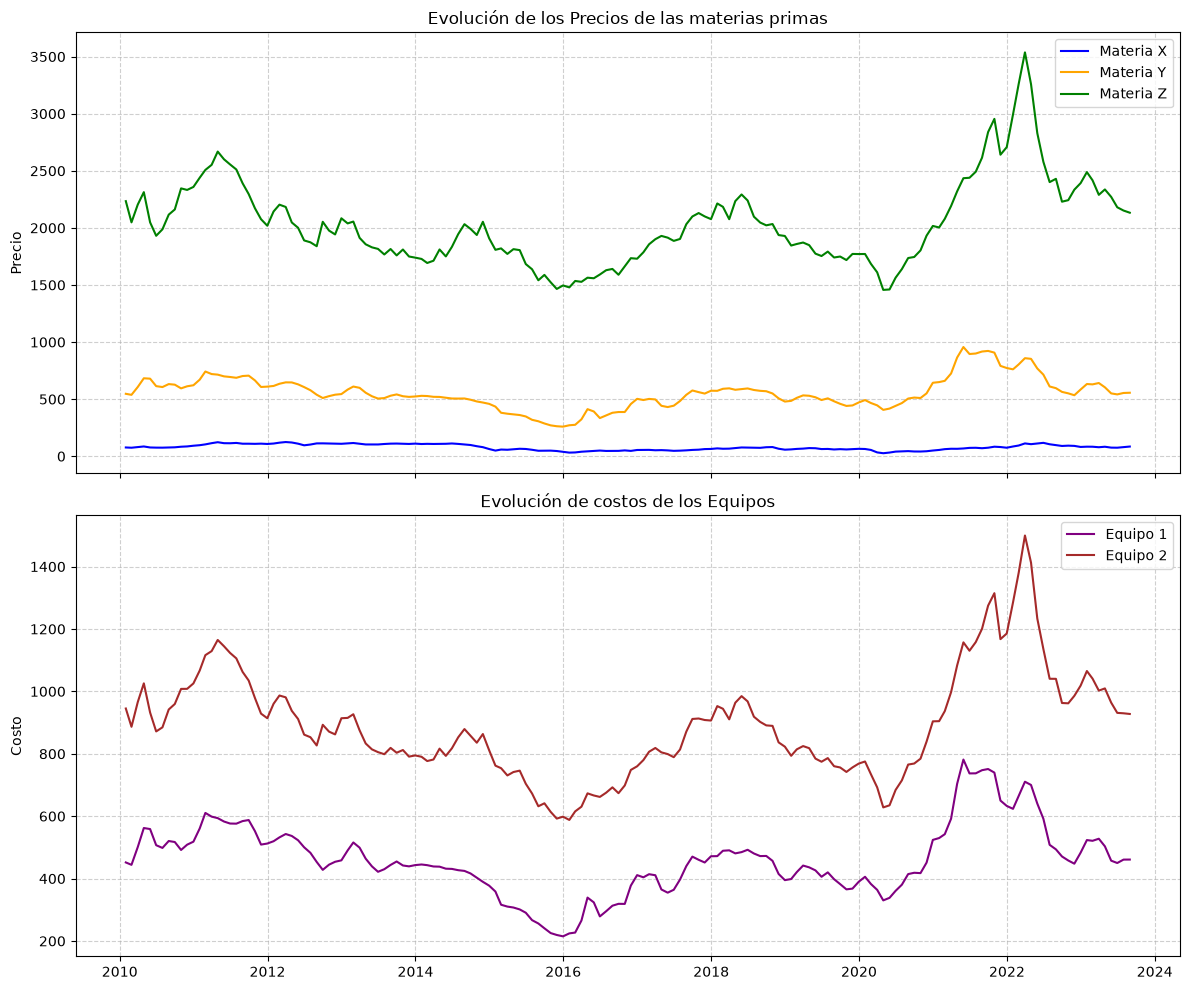

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Materias Primas
ax1.plot(df_por_mes.index, df_por_mes['Price_X'], label='Materia X', color='blue')
ax1.plot(df_por_mes.index, df_por_mes['Price_Y'], label='Materia Y', color='orange')
ax1.plot(df_por_mes.index, df_por_mes['Price_Z'], label='Materia Z', color='green')
ax1.set_title("Evolución de los Precios de las materias primas")
ax1.set_ylabel("Precio")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Equipos
ax2.plot(df_por_mes.index, df_por_mes['Price_Equipo1'], label='Equipo 1', color='purple')
ax2.plot(df_por_mes.index, df_por_mes['Price_Equipo2'], label='Equipo 2', color='brown')
ax2.set_title("Evolución de costos de los Equipos")
ax2.set_ylabel("Costo")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Prueba de Engle-Granger

Se utilizó para evaluar si las materias primas y los equipos comparten una relación de equilibrio a largo plazo y se encontró que el costo del equipo 1 tiene relación a largo plazo con la materia prima Z y el equipo 2 tiene relación de equilibrio a largo plazo con las materias primas Y y Z.

In [ ]:
def prueba_cointegracion(df, equipos, materias_primas, alpha=0.05):
    """Función que calcula el estadístico de Engle-Granger, recibe en forma de listas las variables a relacionar y devuelve el p-value"""
    print("Prueba de cointegración Engle-Granger:")
    for equipo in equipos:
        for materia in materias_primas:
            # Se eliminan nulos en pares para mantener las mismas fechas
            df_sin_nulos = df[[equipo, materia]].dropna()
            
            score, pvalue_coint, _ = coint(df_sin_nulos[equipo], df_sin_nulos[materia])
            
            if pvalue_coint < alpha:
                print(f"{equipo} y {materia}: Existe cointegración (p-value: {pvalue_coint:.4f})")
            else:
                print(f"{equipo} y {materia}: No están cointegrados (p-value: {pvalue_coint:.4f})")


In [14]:
lista_equipos = ['Price_Equipo1', 'Price_Equipo2']
lista_materias = ['Price_X', 'Price_Y', 'Price_Z']

prueba_cointegracion(df_por_mes, lista_equipos, lista_materias)

Prueba de cointegración Engle-Granger:
Price_Equipo1 y Price_X: No están cointegrados (p-value: 0.5549)
Price_Equipo1 y Price_Y: No están cointegrados (p-value: 0.2183)
Price_Equipo1 y Price_Z: Existe cointegración (p-value: 0.0336)
Price_Equipo2 y Price_X: No están cointegrados (p-value: 0.5659)
Price_Equipo2 y Price_Y: Existe cointegración (p-value: 0.0147)
Price_Equipo2 y Price_Z: Existe cointegración (p-value: 0.0264)


### Modelo de Regresión sin intercepto

A manera explicativa para corroborar cómo se relacionan históricamente los precios de las materias primas con el de los equipos se realizó un modelo de regresión sin intercepto esto dado a que si el costo de las materias primas tiende a 0, el costo del equipo también (esto al ignorar gastos fijos, se detalla más en el informe). 

- Se observó que para el equipo 1 el costo depende significativante un 20% del precio de X y 80% del precio de Y, el precio de Z no tiene valor pedictivo. 
- Para el equipo 2 se observó que los precios de las 3 materias primas aportan en la misma medida valor predictivo (33.33%).

In [30]:
# No se usa sm.add_constant() para no incluir el intercepto
X_features = df_por_mes[['Price_X', 'Price_Y', 'Price_Z']]

print("Modelo de Regresión explicativo para el precio del Equipo 1:")
modelo_eq1 = sm.OLS(df_por_mes['Price_Equipo1'].dropna(), X_features.dropna()).fit()
print(modelo_eq1.summary())



Modelo de Regresión explicativo para el precio del Equipo 1:
                                 OLS Regression Results                                
Dep. Variable:          Price_Equipo1   R-squared (uncentered):                   1.000
Model:                            OLS   Adj. R-squared (uncentered):              1.000
Method:                 Least Squares   F-statistic:                          3.700e+06
Date:                Sat, 21 Nov 2026   Prob (F-statistic):                        0.00
Time:                        23:00:37   Log-Likelihood:                         -329.45
No. Observations:                 164   AIC:                                      664.9
Df Residuals:                     161   BIC:                                      674.2
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|     

In [16]:
print("Modelo de Regresión explicativo para el precio del Equipo 2:")
modelo_eq2 = sm.OLS(df_por_mes['Price_Equipo2'].dropna(), X_features.dropna()).fit()
print(modelo_eq2.summary())

Modelo de Regresión explicativo para el precio del Equipo 2:
                                 OLS Regression Results                                
Dep. Variable:          Price_Equipo2   R-squared (uncentered):                   1.000
Model:                            OLS   Adj. R-squared (uncentered):              1.000
Method:                 Least Squares   F-statistic:                          6.194e+06
Date:                Sat, 21 Nov 2026   Prob (F-statistic):                        0.00
Time:                        18:41:09   Log-Likelihood:                         -393.54
No. Observations:                 164   AIC:                                      793.1
Df Residuals:                     161   BIC:                                      802.4
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|     